<a href="https://colab.research.google.com/github/arjr2872003-dot/EV-Energy-Consumption-Analysis/blob/main/Milestone4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor


In [4]:
df = pd.read_csv("/content/EV_Energy_Consumption_Dataset.csv")


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Vehicle_ID              5000 non-null   int64  
 1   Timestamp               5000 non-null   object 
 2   Speed_kmh               5000 non-null   float64
 3   Acceleration_ms2        5000 non-null   float64
 4   Battery_State_%         5000 non-null   float64
 5   Battery_Voltage_V       5000 non-null   float64
 6   Battery_Temperature_C   5000 non-null   float64
 7   Driving_Mode            5000 non-null   int64  
 8   Road_Type               5000 non-null   int64  
 9   Traffic_Condition       5000 non-null   int64  
 10  Slope_%                 5000 non-null   float64
 11  Weather_Condition       5000 non-null   int64  
 12  Temperature_C           5000 non-null   float64
 13  Humidity_%              5000 non-null   float64
 14  Wind_Speed_ms           5000 non-null   

In [10]:

median_energy = df["Energy_Consumption_kWh"].median()
df["Energy_Class"] = (df["Energy_Consumption_kWh"] > median_energy).astype(int)

X = df.drop(
    columns=[
        "Vehicle_ID",
        "Timestamp",
        "Energy_Consumption_kWh",
        "Energy_Class",
    ]
)
y = df["Energy_Class"]

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (5000, 16)
Target shape (y): (5000,)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape after scaling:", X_train_scaled.shape)
print("X_test shape after scaling:", X_test_scaled.shape)

X_train shape after scaling: (4000, 16)
X_test shape after scaling: (1000, 16)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("Models trained successfully!")

Models trained successfully!



================ Logistic Regression ================
Accuracy Score: 0.92

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92       500
           1       0.92      0.92      0.92       500

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



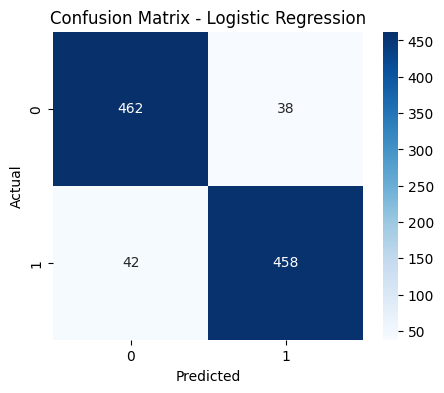


================ KNN ================
Accuracy Score: 0.842

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.82      0.84       500
           1       0.83      0.86      0.85       500

    accuracy                           0.84      1000
   macro avg       0.84      0.84      0.84      1000
weighted avg       0.84      0.84      0.84      1000



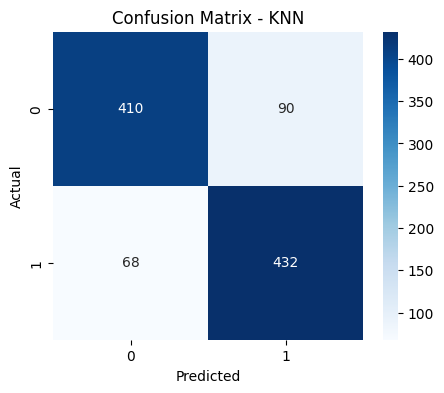

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models = {"Logistic Regression": log_reg, "KNN": knn}

for name, model in models.items():
    print(f"\n================ {name} ================")


    y_pred = model.predict(X_test_scaled)


    print("Accuracy Score:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))


    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [15]:
from sklearn.tree import DecisionTreeClassifier


dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train_scaled, y_train)


y_pred_dt = dt_model.predict(X_test_scaled)

print("=== Decision Tree Results ===")
print("Accuracy Score:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))




=== Decision Tree Results ===
Accuracy Score: 0.867

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.86      0.87       500
           1       0.86      0.87      0.87       500

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000



In [16]:
from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)

print("=== Random Forest Results ===")
print("Accuracy Score:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))



=== Random Forest Results ===
Accuracy Score: 0.904

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.91      0.90       500
           1       0.91      0.90      0.90       500

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000



=== Model Performance Ranking ===
                 Model  Accuracy
0  Logistic Regression     0.920
1        Random Forest     0.904
2        Decision Tree     0.867
3                  KNN     0.842


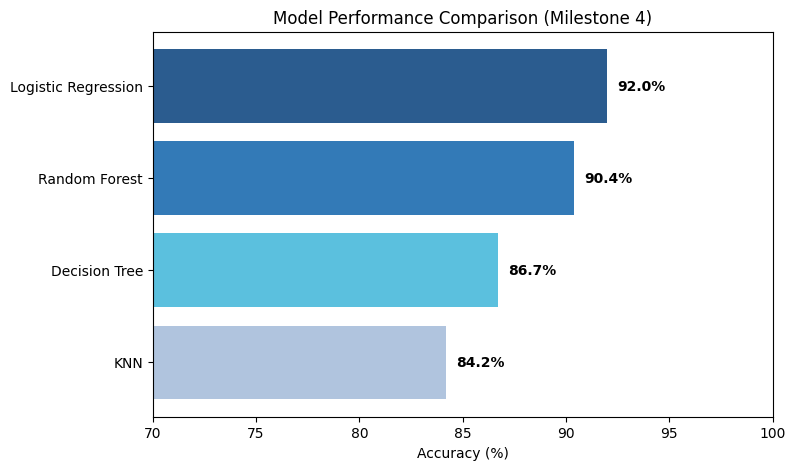

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. حساب دقة كل نموذج وتخزينها في قاموس
model_accuracies = {
    "Logistic Regression": accuracy_score(y_test, log_reg.predict(X_test_scaled)),
    "Random Forest": accuracy_score(y_test, rf_model.predict(X_test_scaled)),
    "Decision Tree": accuracy_score(y_test, dt_model.predict(X_test_scaled)),
    "KNN": accuracy_score(y_test, knn.predict(X_test_scaled)),
}

# 2. تحويل النتائج إلى جدول (DataFrame) وترتيبها تنازلياً من الأعلى للأقل دقة
df_results = (
    pd.DataFrame(list(model_accuracies.items()), columns=["Model", "Accuracy"])
    .sort_values(by="Accuracy", ascending=False)
    .reset_index(drop=True)
)

print("=== Model Performance Ranking ===")
print(df_results)

# 3. رسم بياني يوضح ترتيب النماذج بوضوح
plt.figure(figsize=(8, 5))
bars = plt.barh(
    df_results["Model"],
    df_results["Accuracy"] * 100,
    color=["#2b5c8f", "#337ab7", "#5bc0de", "#b0c4de"],
)
plt.xlabel("Accuracy (%)")
plt.title("Model Performance Comparison (Milestone 4)")
plt.xlim(70, 100)

# إضافة النسبة المئوية بجانب كل عمود في الرسم
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

plt.gca().invert_yaxis()
plt.show()